# 01 · Data Validation & Cleaning
**Project:** Resume Screening and Role Matching Using NLP — *TalentBridge Solutions Pvt. Ltd.*

### Business problem
TalentBridge screens thousands of resumes every week. Keyword filters miss candidates who write skills differently
(e.g. *"Pyhton"*, *"Powe rBI"*), recruiters shortlist inconsistently, and a lot of time goes into reading profiles that
clearly do not fit. The goal is an **NLP-based matching engine** that gives every candidate a **fit score** for a job,
ranks them, and explains *why*.

### Analytical objectives (what "done" looks like)
| # | Objective | How it is measured |
|---|---|---|
| 1 | Clean, trustworthy candidate data | 100% of skill tokens mapped to a standard skill; all logic errors fixed or flagged |
| 2 | Fit score for every candidate × job | Score between 0 and 1 for 5,000 candidates × 10 job descriptions |
| 3 | Rank strong candidates on top | Precision@20 and NDCG@20 per job |
| 4 | Explainable decisions | Every shortlisted candidate gets a plain-English reason |
| 5 | Less recruiter effort | % of resumes a recruiter no longer needs to read manually |

### What this notebook does
1. Loads the raw data and the data definition
2. Checks missing values, duplicates, value ranges and logical consistency
3. Fixes noisy / misspelt skills with fuzzy matching
4. Saves a cleaned dataset for the next notebooks

In [1]:
# --- Setup -----------------------------------------------------------
# Add the project root folder to the Python path so "src" can be imported
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

# Standard libraries for data handling and charts
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")          # hide library warnings so the output stays readable
pd.set_option("display.max_columns", 60)   # show all columns when printing a dataframe
pd.set_option("display.max_colwidth", 80)  # do not cut long text too early

# Project settings: file paths, colours and the chart style
from src.config import *
from src.plot_style import set_style, save
set_style()

## 1. Load the raw data and the data definition

In [2]:
# Read the raw resume data exactly as it was given
raw = pd.read_csv(RAW_DATA)

# Read the data dictionary so the meaning of every column is at hand
data_def = pd.read_excel(ROOT / "Data Definition.xlsx")

print("Rows, columns:", raw.shape)
raw.head(3)

Rows, columns: (5000, 34)


,candidate_id,resume_file_name,candidate_name,primary_domain,primary_role,years_experience,highest_education,education_field,institution_tier,technical_skills_raw,tools_platforms_raw,soft_skills_raw,experience_summary,project_summary,key_achievements,management_experience_flag,people_management_flag,project_management_experience_flag,agile_scrum_experience_flag,client_facing_experience_flag,delivery_lead_experience_flag,cloud_experience_flag,ml_experience_flag,compliance_experience_flag,enterprise_systems_experience_flag,offshore_onsite_model_experience_flag,multi_vendor_coordination_flag,process_compliance_experience_flag,documentation_heavy_role_flag,mentoring_experience_flag,stakeholder_management_experience_flag,resume_length_words,keyword_density_score,profile_completeness_score
0,CND_100001,DataAnalyst_1.pdf,Candidate_1,Data Science,Data Analyst,7,LLM,Mathematics,Tier-1,"Machine Learning, Power BI, Pandas, Python","AWS, ServiceNow","Leadership, Teamwork",Hands-on data science professional with 7+ years of end-to-end delivery expe...,"Delivered project components on time and within scope, coordinating with tea...",Supported initiatives that increased team productivity by 9% and reduced rew...,0,0,1,1,1,0,0,1,0,1,1,1,1,0,1,1,56,0.74,0.61
1,CND_100002,profile_2.pdf,Candidate_2,IT,Senior Software Engineer,10,Masters,Computer Science,Tier-2,"Kubernetes, Git, Docker, Python","AWS, Jira","Teamwork, Communication","Over 10 years delivering solutions in it, collaborating with cross-functiona...","Led implementation of it projects for enterprise clients, focusing on scalab...","Contributed to 43% improvement in key KPIs such as throughput, response time...",1,1,1,1,1,1,0,0,0,1,1,1,1,1,1,1,54,0.89,0.89
2,CND_100003,Legal_candidate_3.pdf,Candidate_3,Legal,Compliance Officer,7,LLM,Law,Tier-1,"Due Diligence, Legal Research, Compliance, Contract Drafting","ServiceNow, AWS","Teamwork, Leadership",Hands-on legal professional with 7+ years of end-to-end delivery experience ...,"Delivered project components on time and within scope, coordinating with tea...",Improved process efficiency by 23% and helped reduce incidents or defects th...,0,0,1,0,1,0,0,0,1,1,1,1,1,1,1,1,57,0.40,0.56


In [3]:
# Quick look at column types - text columns show as 'object', numbers as int/float
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 34 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   candidate_id                            5000 non-null   object 
 1   resume_file_name                        5000 non-null   object 
 2   candidate_name                          5000 non-null   object 
 3   primary_domain                          5000 non-null   object 
 4   primary_role                            5000 non-null   object 
 5   years_experience                        5000 non-null   int64  
 6   highest_education                       4730 non-null   object 
 7   education_field                         4763 non-null   object 
 8   institution_tier                        5000 non-null   object 
 9   technical_skills_raw                    5000 non-null   object 
 10  tools_platforms_raw                     5000 non-null   obje

In [4]:
# Show the data definition (column -> business meaning)
data_def

,Column Name,Description,Business Meaning
0,candidate_id,Unique identifier for each candidate,"Used for tracking, indexing and mapping candidate records across systems"
1,resume_file_name,Original filename of the resume,Mimics real-world ATS uploads; helps identify duplicate or versioned resumes
2,candidate_name,Placeholder name for candidate,Used for personalization and referencing (not used for modeling)
3,primary_domain,"Domain/category (IT, Data Science, HR, Legal, etc.)",Helps understand candidate’s functional background and expected role alignment
4,primary_role,Candidate’s stated role or designation,Strong indicator of job match relevance
5,years_experience,Total years of professional experience,Key signal of seniority and suitability for role levels
6,highest_education,"Highest qualification (e.g., Bachelors, Masters, MBA)",Determines academic suitability or minimum qualification requirements
7,education_field,"Field of study (CS, Statistics, Law, HR, etc.)",Helps assess domain relevance for technical or specialist roles
8,institution_tier,Category of educational institution (Tier-1/2/3),Used by many enterprises as a proxy for baseline academic quality
9,technical_skills_raw,Raw extracted technical skills (with noise),Requires NLP cleaning; primary indicator of mandatory skill alignment


## 2. Missing values
Missing data can silently bias a score (for example a candidate with no education listed could be unfairly pushed down).

In [5]:
# Count missing values in every column and keep only the columns that have some
missing = raw.isna().sum()
missing = missing[missing > 0].to_frame("missing_count")
missing["missing_pct"] = (missing["missing_count"] / len(raw) * 100).round(2)
missing

,missing_count,missing_pct
highest_education,270,5.40
education_field,237,4.74


In [6]:
# Check whether the same rows are missing both education columns, or different rows
both = (raw["highest_education"].isna() & raw["education_field"].isna()).sum()
either = (raw["highest_education"].isna() | raw["education_field"].isna()).sum()
print(f"Rows missing BOTH education columns : {both}")
print(f"Rows missing AT LEAST ONE           : {either}  ({either/len(raw):.1%} of all candidates)")

Rows missing BOTH education columns : 8
Rows missing AT LEAST ONE           : 499  (10.0% of all candidates)


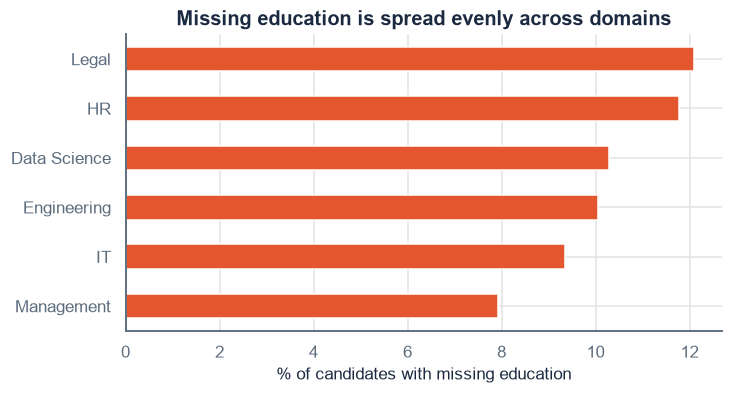

In [7]:
# Are the missing values concentrated in one domain? (if yes, filling them could bias that domain)
miss_by_domain = (raw.assign(edu_missing=raw["highest_education"].isna() | raw["education_field"].isna())
                     .groupby("primary_domain")["edu_missing"].mean().sort_values())

fig, ax = plt.subplots(figsize=(7, 3.5))
miss_by_domain.mul(100).plot.barh(ax=ax, color=COLORS["coral"])
ax.set_xlabel("% of candidates with missing education")
ax.set_ylabel("")
ax.set_title("Missing education is spread evenly across domains")
save(fig, "01_missing_by_domain")
plt.show()

**Finding:** about 10% of candidates miss at least one education field, spread evenly across domains (≈ random).
**Decision:** do **not** guess the degree. Fill with `"Not Specified"` and keep a flag column, so the scoring can give
a *neutral* education score instead of a penalty.

## 3. Duplicates

In [8]:
# Check for duplicates at different levels
checks = {
    "Fully duplicated rows": raw.duplicated().sum(),
    "Duplicated candidate_id": raw["candidate_id"].duplicated().sum(),
    "Duplicated resume_file_name": raw["resume_file_name"].duplicated().sum(),
    # same resume content uploaded twice under a different id / name
    "Duplicated resume content (ignoring id, name, file)": raw.drop(
        columns=["candidate_id", "candidate_name", "resume_file_name"]).duplicated().sum(),
}
pd.Series(checks, name="count").to_frame()

,count
Fully duplicated rows,0
Duplicated candidate_id,0
Duplicated resume_file_name,0
"Duplicated resume content (ignoring id, name, file)",0


**Finding:** no duplicated candidates or re-uploaded resumes, so nothing has to be removed.

## 4. Value range checks

In [9]:
# Every *_flag column should only contain 0 or 1
flag_cols = [c for c in raw.columns if c.endswith("_flag")]
bad_flags = {c: sorted(raw[c].unique()) for c in flag_cols if not set(raw[c].unique()) <= {0, 1}}
print("Flag columns with values other than 0/1:", bad_flags if bad_flags else "none")

# The two ATS scores are described as 0-1 scores
for col in ["keyword_density_score", "profile_completeness_score"]:
    ok = raw[col].between(0, 1).all()
    print(f"{col}: min={raw[col].min()}, max={raw[col].max()}, all within 0-1 -> {ok}")

# Years of experience should be positive and realistic
print("years_experience range:", raw["years_experience"].min(), "to", raw["years_experience"].max())

Flag columns with values other than 0/1: none
keyword_density_score: min=0.25, max=0.9, all within 0-1 -> True
profile_completeness_score: min=0.55, max=0.95, all within 0-1 -> True
years_experience range: 1 to 20


Resume length IQR limits: 47 to 63 words -> outliers: 0


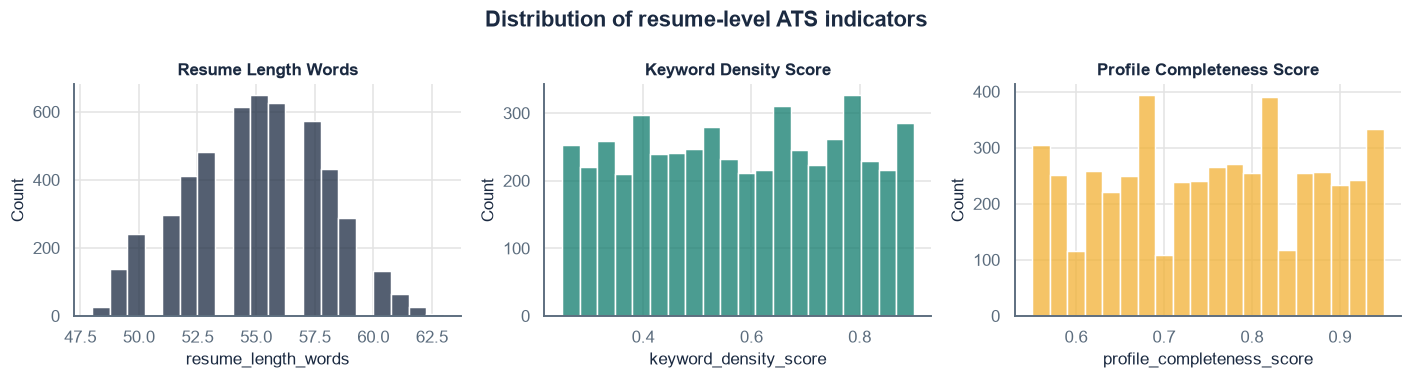

In [10]:
# Look for outliers in resume length using the IQR rule (values far outside the middle 50%)
q1, q3 = raw["resume_length_words"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = raw[(raw["resume_length_words"] < low) | (raw["resume_length_words"] > high)]
print(f"Resume length IQR limits: {low:.0f} to {high:.0f} words -> outliers: {len(outliers)}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col, colr in zip(axes, ["resume_length_words", "keyword_density_score", "profile_completeness_score"],
                         [COLORS["ink"], COLORS["teal"], COLORS["mustard"]]):
    sns.histplot(raw[col], ax=ax, color=colr, bins=20)
    ax.set_title(col.replace("_", " ").title(), fontsize=11)
fig.suptitle("Distribution of resume-level ATS indicators", fontweight="bold", color=COLORS["ink"])
fig.tight_layout()
save(fig, "01_ats_distributions")
plt.show()

**Finding:** all values are inside valid ranges. Resumes are short (48–63 words) because they are *parsed summaries*,
so length is not a strong quality signal on its own. Keyword density above 0.85 is treated later as possible
**keyword stuffing** (a known trick to game ATS systems).

## 5. Logical consistency checks

In [11]:
from src.cleaning import seniority_from_role, role_from_filename, _key

logic = {}

# (a) Seniority in the title vs years of experience
seniority = raw["primary_role"].apply(seniority_from_role)
logic["Junior title with > 5 years"] = ((seniority == "Junior") & (raw["years_experience"] > 5)).sum()
logic["Senior title with < 5 years"] = ((seniority == "Senior") & (raw["years_experience"] < 5)).sum()

# (b) Years written in the experience summary vs the years_experience column
years_in_text = raw["experience_summary"].str.extract(r"(\d+)")[0].astype(float)
logic["Summary years != years_experience"] = (years_in_text != raw["years_experience"]).sum()

# (c) Domain written in the summary vs primary_domain
logic["Summary domain != primary_domain"] = (~raw.apply(
    lambda r: r["primary_domain"].lower() in r["experience_summary"].lower(), axis=1)).sum()

# (d) LLM is a Master of LAWS - it should only go with the Law field
logic["LLM degree with a non-Law field"] = ((raw["highest_education"] == "LLM")
                                            & raw["education_field"].notna()
                                            & (raw["education_field"] != "Law")).sum()

# (e) Someone who manages people must also have management experience
logic["People manager without management flag"] = ((raw["people_management_flag"] == 1)
                                                   & (raw["management_experience_flag"] == 0)).sum()

# (f) Role written in the file name vs primary_role (only for files that contain a role)
file_role = raw["resume_file_name"].apply(role_from_filename)
role_key = raw["primary_role"].apply(_key)
domain_key = raw["primary_domain"].apply(_key)
has_role = file_role.notna() & ~file_role.isin(["", "it", "datascience", "hr", "legal", "engineering", "management"])
logic["File name role != primary_role"] = (has_role & (file_role != role_key)).sum()
logic["File name domain != primary_domain"] = (file_role.isin(["it", "datascience", "hr", "legal", "engineering", "management"])
                                               & (file_role != domain_key)).sum()

pd.Series(logic, name="violations").to_frame()

,violations
Junior title with > 5 years,0
Senior title with < 5 years,0
Summary years != years_experience,0
Summary domain != primary_domain,0
LLM degree with a non-Law field,1063
People manager without management flag,0
File name role != primary_role,0
File name domain != primary_domain,0


In [12]:
# Show the education problem in detail - which fields come with an 'LLM' degree?
pd.crosstab(raw["education_field"].fillna("Missing"), raw["highest_education"].fillna("Missing"))

highest_education,Bachelors,LLM,MBA,Masters,Missing
education_field,,,,,
Business Administration,13,10,16,18,2
Computer Science,303,332,306,302,68
Data Science,75,88,82,74,21
Human Resources,67,57,47,57,15
Information Technology,311,306,313,340,61
Law,63,95,96,95,28
Management,15,19,21,16,6
Mathematics,69,68,82,82,15
Mechanical Engineering,41,43,41,45,8


**Findings**
- Seniority, years and domain are consistent across title, summary and file name — good news for trusting these fields.
- **1,063 candidates hold an "LLM" in a non-law subject** (e.g. *LLM in Computer Science*). This is impossible, so it is
  treated as a parsing error. **Fix:** re-label these as a general `"Masters"` (same level of study) and keep a flag.
- People-management always comes with management experience, as expected.

## 6. Redundant (duplicated) columns

In [13]:
# Compare every pair of flag columns - if two columns are identical in all 5,000 rows,
# one of them adds no new information
import itertools
identical = [(a, b) for a, b in itertools.combinations(flag_cols, 2) if (raw[a] == raw[b]).all()]
pd.DataFrame(identical, columns=["column_a", "column_b"])

,column_a,column_b
0,project_management_experience_flag,stakeholder_management_experience_flag
1,client_facing_experience_flag,process_compliance_experience_flag
2,enterprise_systems_experience_flag,mentoring_experience_flag


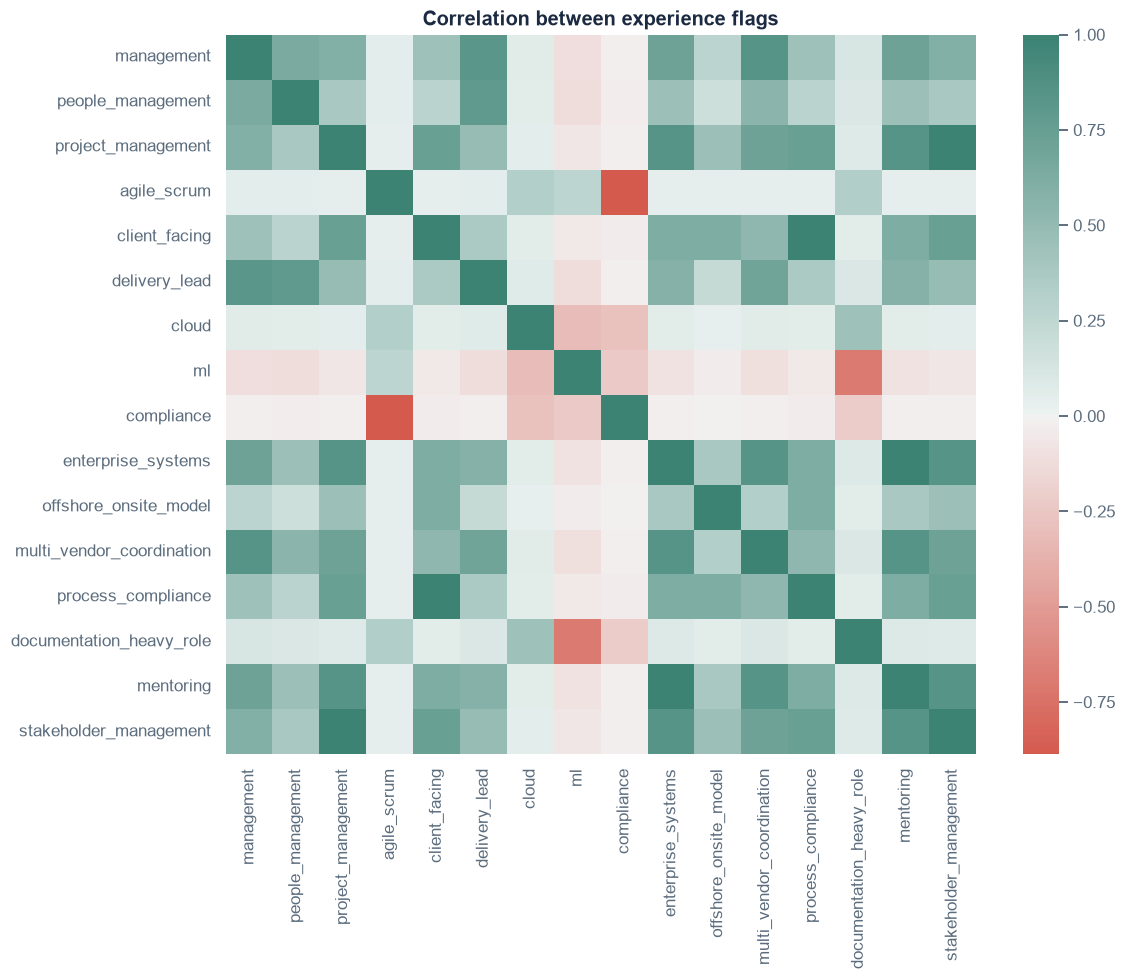

In [14]:
# Correlation heatmap of all experience flags
corr = raw[flag_cols].corr()
fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(corr, cmap=sns.diverging_palette(15, 170, as_cmap=True), center=0, ax=ax,
            xticklabels=[c.replace("_flag", "").replace("_experience", "") for c in flag_cols],
            yticklabels=[c.replace("_flag", "").replace("_experience", "") for c in flag_cols])
ax.set_title("Correlation between experience flags")
save(fig, "01_flag_correlation")
plt.show()

In [15]:
# The ML flag is also exactly the same as "domain == Data Science"
print(pd.crosstab(raw["primary_domain"], raw["ml_experience_flag"]))

ml_experience_flag     0     1
primary_domain                
Data Science           0  1002
Engineering          189     0
HR                   501     0
IT                  2772     0
Legal                397     0
Management           139     0


**Finding:** three pairs of flags are **exact copies** of each other, and `ml_experience_flag` simply repeats the domain.
**Decision:** keep the columns (they are used by job descriptions), but in the ML models only one column of each
identical pair is used, so the model does not double-count the same information.

## 7. Noisy skill representations
This is the core NLP cleaning step. Each resume lists 4 skills, but many are misspelt.

In [16]:
from src.cleaning import (build_skill_correction_table, clean_skill_list, clean_tool_list,
                          CANONICAL_SKILLS, fix_education, clean_text)

# Build a table of every distinct raw token and the skill it maps to
corrections = build_skill_correction_table(raw["technical_skills_raw"])
print("Distinct raw skill tokens :", len(corrections))
print("Distinct canonical skills :", corrections["canonical_skill"].nunique())
print()
print(corrections["method"].value_counts().rename("tokens fixed by each method"))

Distinct raw skill tokens : 212
Distinct canonical skills : 30

method
fuzzy      165
exact       30
spacing     17
Name: tokens fixed by each method, dtype: int64


In [17]:
# Show some examples of each type of correction
corrections[corrections["method"] != "exact"].sort_values("occurrences", ascending=False).head(15)

,raw_token,canonical_skill,method,occurrences
30,Jaav,Java,fuzzy,54
31,Jvaa,Java,fuzzy,50
32,Pythno,Python,fuzzy,47
33,Lniux,Linux,fuzzy,46
34,Pyhton,Python,fuzzy,46
35,Linxu,Linux,fuzzy,40
36,Ptyhon,Python,fuzzy,39
37,Liunx,Linux,fuzzy,36
38,Pytohn,Python,fuzzy,35
39,Dockre,Docker,fuzzy,28


In [18]:
# How many resumes contained at least one misspelt skill?
from src.cleaning import split_skills, normalize_skill
has_typo = raw["technical_skills_raw"].apply(
    lambda s: any(normalize_skill(t)[1] in ("fuzzy", "spacing") for t in split_skills(s)))
print(f"Resumes with at least one noisy skill: {has_typo.sum()} ({has_typo.mean():.1%})")

# A plain keyword filter for 'Python' vs the cleaned version
kw_python = raw["technical_skills_raw"].str.contains(r"\bPython\b").sum()
clean_python = raw["technical_skills_raw"].apply(lambda s: "Python" in clean_skill_list(s)).sum()
print(f"Exact keyword search finds 'Python' in {kw_python} resumes; after cleaning: {clean_python} "
      f"(+{clean_python - kw_python} candidates a keyword filter would have missed)")

Resumes with at least one noisy skill: 1040 (20.8%)
Exact keyword search finds 'Python' in 1796 resumes; after cleaning: 1963 (+167 candidates a keyword filter would have missed)


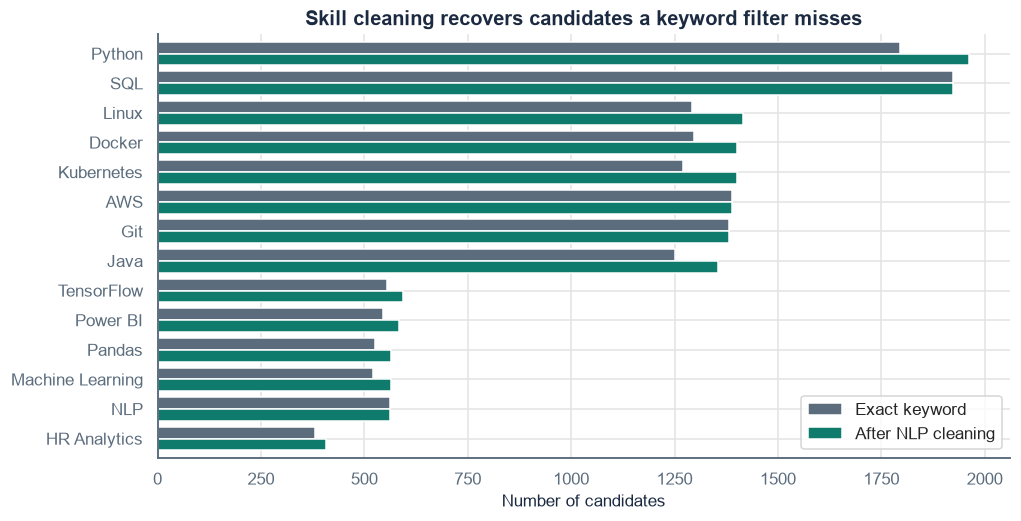

In [19]:
# Chart: how many candidates each skill reaches before vs after cleaning
before = pd.Series([t for s in raw["technical_skills_raw"] for t in split_skills(s)]).value_counts()
after = pd.Series([t for s in raw["technical_skills_raw"] for t in clean_skill_list(s)]).value_counts()
compare = pd.DataFrame({"Exact keyword": before.reindex(after.index).fillna(0),
                        "After NLP cleaning": after}).head(14)

fig, ax = plt.subplots(figsize=(10, 5))
compare.plot.barh(ax=ax, color=[COLORS["slate"], COLORS["teal"]], width=0.8)
ax.invert_yaxis()
ax.set_xlabel("Number of candidates")
ax.set_title("Skill cleaning recovers candidates a keyword filter misses")
save(fig, "01_skill_cleaning_gain")
plt.show()

## 8. Completeness of the text fields

In [20]:
# Length of each free-text field and how many unique sentences exist
text_cols = ["experience_summary", "project_summary", "key_achievements"]
summary = pd.DataFrame({
    "empty_values": [(raw[c].fillna("").str.strip() == "").sum() for c in text_cols],
    "min_chars": [raw[c].str.len().min() for c in text_cols],
    "max_chars": [raw[c].str.len().max() for c in text_cols],
    "unique_texts": [raw[c].nunique() for c in text_cols],
    # after removing numbers, how many different sentence templates are there?
    "unique_templates": [raw[c].str.replace(r"\d+", "#", regex=True).str.lower().nunique() for c in text_cols],
}, index=text_cols)
summary

,empty_values,min_chars,max_chars,unique_texts,unique_templates
experience_summary,0,123,149,251,18
project_summary,0,91,119,13,13
key_achievements,0,90,102,114,3


**Finding:** no text field is empty, but the summaries come from only a handful of sentence **templates**
(the numbers and domain name change). This means text similarity alone will not separate candidates very well,
so the matching engine must rely mainly on **cleaned skills and structured experience features**, with NLP
similarity as a supporting signal. This is an important assumption for the rest of the project.

## 9. Apply all fixes and save the cleaned dataset

In [21]:
clean = raw.copy()

# 1) Education: fix 'LLM' in non-law fields, fill missing values with 'Not Specified' + flags
clean = fix_education(clean)

# 2) Skills: map every token to its canonical name and remove duplicates
clean["skills_clean"] = clean["technical_skills_raw"].apply(clean_skill_list)
clean["tools_clean"] = clean["tools_platforms_raw"].apply(clean_tool_list)
clean["soft_skills_clean"] = clean["soft_skills_raw"].apply(clean_tool_list)
clean["skill_typo_flag"] = has_typo.astype(int)

# 3) Seniority level read from the job title (used for seniority matching later)
clean["seniority_level"] = clean["primary_role"].apply(seniority_from_role)

# 4) Light text normalisation for the NLP step
for c in text_cols:
    clean[c + "_clean"] = clean[c].apply(clean_text)

# quick check: no missing values should remain in the columns used for modelling
print("Missing values left:", clean.drop(columns=["highest_education", "education_field"]).isna().sum().sum())
clean[["candidate_id", "technical_skills_raw", "skills_clean", "highest_education",
       "education_field", "education_corrected_flag", "seniority_level"]].head(8)

Missing values left: 0


,candidate_id,technical_skills_raw,skills_clean,highest_education,education_field,education_corrected_flag,seniority_level
0,CND_100001,"Machine Learning, Power BI, Pandas, Python","[Machine Learning, Pandas, Power BI, Python]",Masters,Mathematics,1,Mid
1,CND_100002,"Kubernetes, Git, Docker, Python","[Docker, Git, Kubernetes, Python]",Masters,Computer Science,0,Senior
2,CND_100003,"Due Diligence, Legal Research, Compliance, Contract Drafting","[Compliance, Contract Drafting, Due Diligence, Legal Research]",LLM,Law,0,Mid
3,CND_100004,"Kubernetes, AWS, SQL, Docker","[AWS, Docker, Kubernetes, SQL]",Masters,Computer Science,1,Senior
4,CND_100005,"Java, Kubernetes, Git, AWS","[AWS, Git, Java, Kubernetes]",Masters,Information Technology,0,Mid
5,CND_100006,"NLP, Machine Learning, SQL, Python","[Machine Learning, NLP, Python, SQL]",Bachelors,Mathematics,0,Junior
6,CND_100007,"Kubernetes, AWS, SQL, Java","[AWS, Java, Kubernetes, SQL]",Not Specified,Computer Science,0,Mid
7,CND_100008,"Kubernetes, AWS, Java, Git","[AWS, Git, Java, Kubernetes]",Bachelors,Information Technology,0,Mid


In [22]:
# Save. Lists are stored as 'a|b|c' text so they survive the CSV format.
to_save = clean.copy()
for c in ["skills_clean", "tools_clean", "soft_skills_clean"]:
    to_save[c] = to_save[c].apply("|".join)
to_save.to_csv(CLEANED_FILE, index=False)

# Also save the skill correction table so the corrections can be audited by HR / tech teams
corrections.to_csv(OUTPUTS / "skill_correction_table.csv", index=False)
print("Saved:", CLEANED_FILE.name, to_save.shape)

Saved: cleaned_resumes.csv (5000, 44)


## 10. Validation log (summary of every issue and action)

In [23]:
# One table that lists every check, what was found and the action taken (also saved for the report)
validation_log = pd.DataFrame([
    ["Missing highest_education / education_field", f"{either} rows", "Filled with 'Not Specified' + education_missing_flag (neutral score later)"],
    ["'LLM' degree in a non-law field", f"{logic['LLM degree with a non-Law field']} rows", "Re-labelled as 'Masters' + education_corrected_flag"],
    ["Misspelt / badly spaced skills", f"{has_typo.sum()} resumes, {(corrections['method']!='exact').sum()} distinct bad tokens", "Mapped to 30 canonical skills with fuzzy matching (threshold 75)"],
    ["Identical flag columns", f"{len(identical)} pairs", "Kept for JD rules; only one of each pair used in ML"],
    ["ml_experience_flag = Data Science domain", "100% overlap", "Noted as redundant for ML"],
    ["Templated text summaries", f"{summary['unique_templates'].max()} templates max", "NLP similarity used as a supporting signal, not the main one"],
    ["Duplicates (rows / ids / files / content)", "0", "No action needed"],
    ["Seniority vs experience / summary vs years", "0 violations", "No action needed"],
    ["Out-of-range values", "0", "No action needed"],
], columns=["Check", "Result", "Action"])
validation_log.to_csv(OUTPUTS / "validation_log.csv", index=False)
validation_log

,Check,Result,Action
0,Missing highest_education / education_field,499 rows,Filled with 'Not Specified' + education_missing_flag (neutral score later)
1,'LLM' degree in a non-law field,1063 rows,Re-labelled as 'Masters' + education_corrected_flag
2,Misspelt / badly spaced skills,"1040 resumes, 182 distinct bad tokens",Mapped to 30 canonical skills with fuzzy matching (threshold 75)
3,Identical flag columns,3 pairs,Kept for JD rules; only one of each pair used in ML
4,ml_experience_flag = Data Science domain,100% overlap,Noted as redundant for ML
5,Templated text summaries,18 templates max,"NLP similarity used as a supporting signal, not the main one"
6,Duplicates (rows / ids / files / content),0,No action needed
7,Seniority vs experience / summary vs years,0 violations,No action needed
8,Out-of-range values,0,No action needed
